In [11]:
import json
from pathlib import Path
import pandas as pd
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from PIL import Image, UnidentifiedImageError

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
CSV_PATH = DATA_DIR / "styles.csv"
IMG_DIR = DATA_DIR / "images"

In [3]:
assert CSV_PATH.exists(), f"Cannot find {CSV_PATH}. Check where styles.csv is extracted!"
assert IMG_DIR.exists(), f"Cannot find {IMG_DIR}. Check where the images/ folder is!"

In [4]:
df_raw = pd.read_csv(CSV_PATH, on_bad_lines="skip")
print(f"Raw metadata rows loaded: {len(df_raw):,}")
print("Columns:", df_raw.columns.tolist())

Raw metadata rows loaded: 44,424
Columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


In [5]:
df = df_raw.dropna(subset=["id", "articleType"]).copy()
df["id"] = df["id"].astype(int).astype(str)
df["image_path"] = df["id"].apply(lambda x: IMG_DIR / f"{x}.jpg")

In [6]:
df["file_exists"] = df["image_path"].apply(lambda p: p.exists())
missing_files_count = int((~df["file_exists"]).sum())
df_valid = df[df["file_exists"]].copy()

In [7]:
print(f"Rows with missing target/id dropped: {len(df_raw) - len(df)}")
print(f"Missing image files on disk: {missing_files_count}")
print(f"Valid matched records: {len(df_valid):,}")

Rows with missing target/id dropped: 0
Missing image files on disk: 5
Valid matched records: 44,419


In [8]:
class_counts = df_valid["articleType"].value_counts()
print(f"\nTotal unique articleType classes: {len(class_counts)}")
print("\n--- Top 10 Most Frequent Classes ---")
print(class_counts.head(10))
print("\n--- Bottom 10 Least Frequent Classes ---")
print(class_counts.tail(10))


Total unique articleType classes: 142

--- Top 10 Most Frequent Classes ---
articleType
Tshirts         7066
Shirts          3215
Casual Shoes    2845
Watches         2542
Sports Shoes    2036
Kurtas          1844
Tops            1762
Handbags        1759
Heels           1323
Sunglasses      1073
Name: count, dtype: int64

--- Bottom 10 Least Frequent Classes ---
articleType
Rain Trousers          2
Ties and Cufflinks     2
Face Serum and Gel     2
Key chain              2
Shoe Laces             1
Hair Accessory         1
Cushion Covers         1
Mens Grooming Kit      1
Body Wash and Scrub    1
Ipad                   1
Name: count, dtype: int64


In [9]:
for min_samples in [20, 50, 100]:
    kept_classes = class_counts[class_counts >= min_samples].index
    subset_rows = df_valid[df_valid["articleType"].isin(kept_classes)]
    pct = 100 * len(subset_rows) / len(df_valid)
    print(
        f"Threshold >= {min_samples:3d} images/class: "
        f"keeps {len(kept_classes):3d} classes and {len(subset_rows):,} images ({pct:.1f}% of data)"
    )

Threshold >=  20 images/class: keeps  90 classes and 44,020 images (99.1% of data)
Threshold >=  50 images/class: keeps  70 classes and 43,328 images (97.5% of data)
Threshold >= 100 images/class: keeps  54 classes and 42,150 images (94.9% of data)


In [12]:
SEED = 42
MIN_CLASS_COUNT = 100

In [13]:
class_counts = df_valid["articleType"].value_counts()
kept_classes = class_counts[class_counts >= MIN_CLASS_COUNT].index.tolist()
df_curated = df_valid[df_valid["articleType"].isin(kept_classes)].copy()

In [14]:
corrupt_ids = []
non_rgb_count = 0

for idx, row in df_curated.iterrows():
    img_path = row["image_path"]
    if img_path.stat().st_size == 0:
        corrupt_ids.append(row["id"])

In [15]:
for img_path in df_curated["image_path"].sample(n=min(500, len(df_curated)), random_state=SEED):
    try:
        with Image.open(img_path) as img:
            if img.mode != "RGB":
                non_rgb_count += 1
    except (UnidentifiedImageError, OSError):
        corrupt_ids.append(img_path.stem)

if corrupt_ids:
    df_curated = df_curated[~df_curated["id"].isin(corrupt_ids)].copy()

In [16]:
before_dedup = len(df_curated)
df_curated["clean_name"] = df_curated["productDisplayName"].fillna("").str.strip().str.lower()

non_empty_name = df_curated["clean_name"] != ""
df_dedup = pd.concat([
    df_curated[non_empty_name].drop_duplicates(subset=["clean_name", "articleType", "baseColour"], keep="first"),
    df_curated[~non_empty_name]
], ignore_index=True)

In [17]:
final_counts = df_dedup["articleType"].value_counts()
valid_final_classes = final_counts[final_counts >= 50].index.tolist()
df_final = df_dedup[df_dedup["articleType"].isin(valid_final_classes)].copy()
duplicates_removed = before_dedup - len(df_final)

In [18]:
sorted_classes = sorted(df_final["articleType"].unique())
label_to_idx = {cls_name: idx for idx, cls_name in enumerate(sorted_classes)}
idx_to_label = {idx: cls_name for cls_name, idx in label_to_idx.items()}
df_final["label_idx"] = df_final["articleType"].map(label_to_idx)

In [20]:
train_df, temp_df = train_test_split(
    df_final,
    test_size=0.30,
    stratify=df_final["label_idx"],
    random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_idx"],
    random_state=SEED,
)

assert set(train_df["id"]).isdisjoint(set(val_df["id"]))
assert set(train_df["id"]).isdisjoint(set(test_df["id"]))
assert set(val_df["id"]).isdisjoint(set(test_df["id"]))

In [21]:
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
REPORTS_DIR = PROJECT_ROOT / "reports"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

cols_to_save = ["id", "gender", "masterCategory", "subCategory", "articleType", "baseColour", "season", "year", "usage", "productDisplayName", "label_idx"]
train_df[cols_to_save].to_csv(SPLITS_DIR / "train.csv", index=False)
val_df[cols_to_save].to_csv(SPLITS_DIR / "val.csv", index=False)
test_df[cols_to_save].to_csv(SPLITS_DIR / "test.csv", index=False)

with open(SPLITS_DIR / "label_mapping.json", "w") as f:
    json.dump({"label_to_idx": label_to_idx, "idx_to_label": idx_to_label}, f, indent=2)

In [22]:
audit_report = {
    "dataset_name": "Kaggle Fashion Product Images (Small)",
    "seed": SEED,
    "raw_rows_loaded": int(len(df_raw)),
    "missing_image_files_on_disk": int(missing_files_count),
    "corrupt_zero_byte_files": len(corrupt_ids),
    "non_rgb_images_in_500_sample": non_rgb_count,
    "initial_unique_classes": int(len(class_counts)),
    "min_class_frequency_threshold": MIN_CLASS_COUNT,
    "near_duplicate_metadata_rows_removed": int(duplicates_removed),
    "final_curated_classes_C": int(len(sorted_classes)),
    "final_curated_total_images": int(len(df_final)),
    "splits": {
        "train": int(len(train_df)),
        "val": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "leakage_check_passed": True,
}
with open(REPORTS_DIR / "dataset_audit.json", "w") as f:
    json.dump(audit_report, f, indent=2)

print("DATASET AUDIT & SPLIT SUMMARY")
print(json.dumps(audit_report, indent=2))

DATASET AUDIT & SPLIT SUMMARY
{
  "dataset_name": "Kaggle Fashion Product Images (Small)",
  "seed": 42,
  "raw_rows_loaded": 44424,
  "missing_image_files_on_disk": 5,
  "corrupt_zero_byte_files": 0,
  "non_rgb_images_in_500_sample": 3,
  "initial_unique_classes": 142,
  "min_class_frequency_threshold": 100,
  "near_duplicate_metadata_rows_removed": 12283,
  "final_curated_classes_C": 51,
  "final_curated_total_images": 29867,
  "splits": {
    "train": 20906,
    "val": 4480,
    "test": 4481
  },
  "leakage_check_passed": true
}


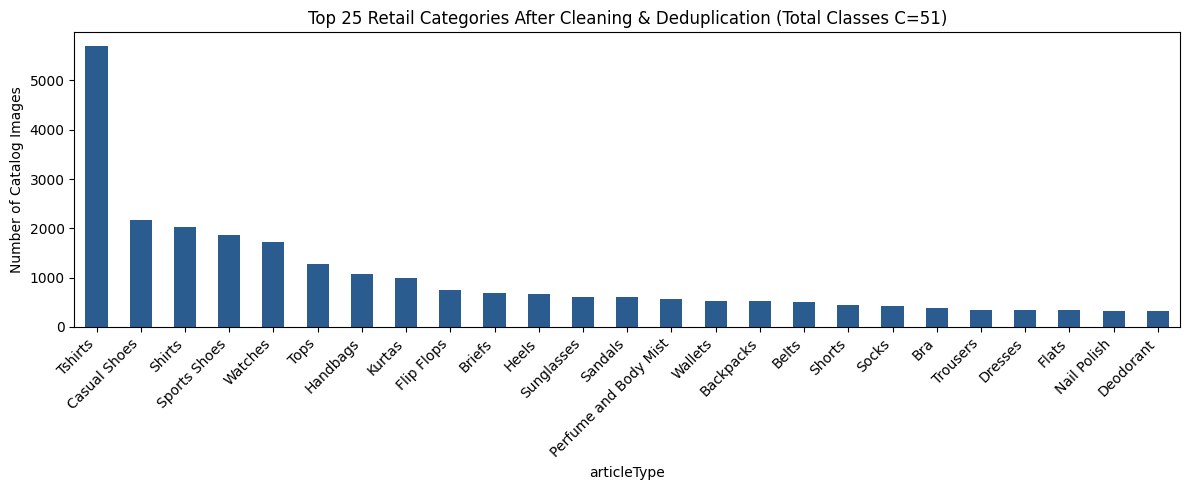

In [23]:
plt.figure(figsize=(12, 5))
df_final["articleType"].value_counts().head(25).plot(kind="bar", color="#2b5c8f")
plt.title(f"Top 25 Retail Categories After Cleaning & Deduplication (Total Classes C={len(sorted_classes)})")
plt.ylabel("Number of Catalog Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "class_distribution_top25.png", dpi=150)
plt.show()